# CatBoost - Deprem Risk Modeli Karsilastirmasi

**Gorev:** ikili siniflandirma - `label_30d` (onumuzdeki 30 gun, 100 km, M>=4.0)

**Veri:** `QuakeMindBackend/apps/earthquake_risk/data/query.csv`

**Bu model:** Mevcut production modeli (risk_engine.py). Referans / baz cizgi.

Butun defterler `common_preprocessing.py` uzerinden AYNI ozellik muhendisligini,
AYNI etiketi ve AYNI walk-forward (TimeSeriesSplit, 5 fold) bolmesini kullanir.
Sonuclar `results/` klasorune yazilir ve `results/leaderboard.csv` guncellenir.

In [1]:
# === COLAB KURULUM ===  (yerelde calistirinca atlanir)
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and not os.path.exists('/content/QuakeMind'):
    !git clone --depth 1 https://github.com/UtBird/QuakeMind.git /content/QuakeMind
if IN_COLAB:
    %cd /content/QuakeMind/model_benchmarks/05_risk_skoru
    %pip install -q catboost xgboost lightgbm shap scikit-learn
print('cwd:', os.getcwd())

cwd: /home/utku/Desktop/QuakeMindLD/QuakeMind/model_benchmarks/05_risk_skoru


In [2]:
# pip install catboost

## 1. Veri

In [3]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# common_preprocessing.py bu klasorde
sys.path.insert(0, str(Path.cwd()))
import common_preprocessing as cp

X, y, df_main = cp.load_dataset()
print('Ornek sayisi     :', len(X))
print('Ozellik sayisi   :', X.shape[1])
print('Pozitif oran     :', round(float(y.mean()), 4))
print('Zaman araligi    :', df_main['time'].min(), '->', df_main['time'].max())
X.head()

Ornek sayisi     : 454
Ozellik sayisi   : 18
Pozitif oran     : 0.6872
Zaman araligi    : 2022-04-29 17:35:34+00:00 -> 2024-10-04 05:57:19+00:00


,latitude,longitude,depth,rolling_mean_7d,rolling_std_7d,rolling_max_7d,event_count_7d,year,month,day,hour,day_of_year,days_since_start,sin_month,cos_month,sin_hour,cos_hour,distance_to_fault
0,37.0540,28.2360,7.91,4.271429,0.464451,5.3,7.0,2022,4,29,17,119,32513,0.866025,-0.500000,-0.965926,-0.258819,28.484295
1,41.1134,44.0631,10.00,4.400000,0.500000,5.3,7.0,2022,5,1,19,121,32515,0.500000,-0.866025,-0.965926,0.258819,340.132781
2,38.1744,26.1468,4.78,4.414286,0.494734,5.3,7.0,2022,5,13,22,133,32527,0.500000,-0.866025,-0.500000,0.866025,47.537137
3,41.1120,44.0650,12.45,4.457143,0.464963,5.3,7.0,2022,5,14,17,134,32528,0.500000,-0.866025,-0.965926,-0.258819,340.206376
4,36.5108,28.5676,57.36,4.428571,0.488925,5.3,7.0,2022,5,15,21,135,32529,0.500000,-0.866025,-0.707107,0.707107,76.871193


## 2. Model tanimi

In [4]:
PARAMS = dict(iterations=800, depth=8, learning_rate=0.03,
              loss_function='Logloss', random_seed=42, verbose=False)

MODEL_NAME = "catboost"

from catboost import CatBoostClassifier
def build_model():
    return CatBoostClassifier(**PARAMS)

def fit_predict(model, X_tr, y_tr, X_te):
    model.fit(X_tr, y_tr)
    return model.predict_proba(X_te)[:, 1]

## 3. Walk-forward degerlendirme

In [5]:
splits = cp.walk_forward_splits(len(X), n_splits=5)
fold_metrics = []
oof_true, oof_prob = [], []

for i, (tr, te) in enumerate(splits, 1):
    X_tr, X_te = X.iloc[tr], X.iloc[te]
    y_tr, y_te = y.iloc[tr], y.iloc[te]

    model = build_model()
    prob = fit_predict(model, X_tr, y_tr, X_te)

    m = cp.evaluate_predictions(y_te, prob)
    fold_metrics.append(m)
    oof_true.append(np.asarray(y_te)); oof_prob.append(np.asarray(prob))
    print(f"fold {i}: ROC-AUC={m['roc_auc']:.3f}  PR-AUC={m['pr_auc']:.3f}  F1={m['f1']:.3f}  n={m['n']}")

agg = cp.aggregate_folds(fold_metrics)
print()
for k in ['roc_auc', 'pr_auc', 'f1', 'precision', 'recall', 'balanced_accuracy', 'brier']:
    print(f"{k:20s}: {agg[k+'_mean']:.3f} +/- {agg[k+'_std']:.3f}")

fold 1: ROC-AUC=0.741  PR-AUC=0.980  F1=0.934  n=75


fold 2: ROC-AUC=0.968  PR-AUC=0.997  F1=0.965  n=75


fold 3: ROC-AUC=0.944  PR-AUC=0.979  F1=0.909  n=75


fold 4: ROC-AUC=0.819  PR-AUC=0.867  F1=0.804  n=75


fold 5: ROC-AUC=0.760  PR-AUC=0.683  F1=0.650  n=75

roc_auc             : 0.846 +/- 0.093
pr_auc              : 0.901 +/- 0.118
f1                  : 0.852 +/- 0.115
precision           : 0.822 +/- 0.154
recall              : 0.898 +/- 0.082
balanced_accuracy   : 0.709 +/- 0.054
brier               : 0.137 +/- 0.073


## 4. Sonucu kaydet

In [6]:
lb = cp.save_result(MODEL_NAME, agg, extra={'params': PARAMS})
print('Kaydedildi -> results/%s.json' % MODEL_NAME)
lb[['model', 'roc_auc_mean', 'pr_auc_mean', 'f1_mean', 'recall_mean', 'precision_mean']]

Kaydedildi -> results/catboost.json


,model,roc_auc_mean,pr_auc_mean,f1_mean,recall_mean,precision_mean
0,catboost,0.84647,0.90111,0.852457,0.897576,0.821658


## 5. ROC ve Precision-Recall egrileri

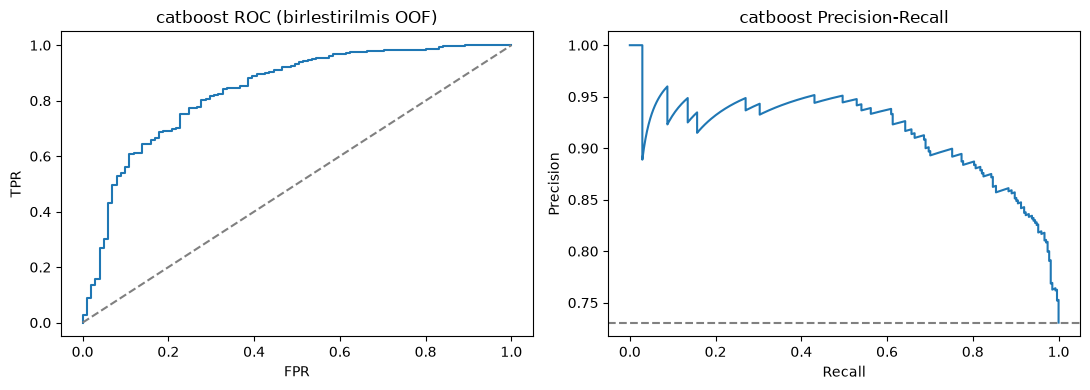

In [7]:
from sklearn.metrics import roc_curve, precision_recall_curve
yt = np.concatenate(oof_true); yp = np.concatenate(oof_prob)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(yt, yp)
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], '--', c='gray')
ax[0].set_title(f'{MODEL_NAME} ROC (birlestirilmis OOF)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR')
prec, rec, _ = precision_recall_curve(yt, yp)
ax[1].plot(rec, prec); ax[1].axhline(float(yt.mean()), ls='--', c='gray')
ax[1].set_title(f'{MODEL_NAME} Precision-Recall'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
plt.tight_layout(); plt.show()